# TorNet: an executed controlled transfer-learning study

We adapt a frozen public radar CNN by training new heads. The target is **current tornado presence**, not future development. All twelve actual fits and the final decision are stored with hashes. This notebook executes the pipeline's verified reuse paths when results already exist, then displays those measured outputs. It does not retune the final holdout. The frozen plan retains its historical status string; actual completion is documented by the receipts and run rows below. Source code is in the accompanying Python modules.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
assert (ROOT / 'planned_config.json').exists(), 'Run from study_tornado'
sys.path.insert(0, str(ROOT))
from run_study import ensure_data, ensure_features
from experiments import train, test_once
config = json.loads((ROOT / 'planned_config.json').read_text())
display(config)

{'study': 'Recent radar history for tornado detection',
 'status': 'Designed and catalog verified; adaptation runs not performed',
 'split_seed': 42,
 'training_seeds': [42, 43, 44],
 'data': {'name': 'MIT TorNet',
  'version': '1.1',
  'years': [2014, 2015],
  'source_partition': 'test',
  'sources': ['https://zenodo.org/records/12637032',
   'https://zenodo.org/records/12655151'],
  'catalog_source': 'https://zenodo.org/records/12636522/files/catalog.csv?download=1',
  'sampling': '2014-2015 source-test examples after source-train episode/event and proximity exclusions; no class balancing or model-score selection',
  'pretraining_catalog_exclusion': 'Discard every selected clip whose episode_id or event_id appears in any2013-2022 source train row, including authors validation years',
  'source_train_proximity_minutes': 30,
  'source_train_proximity_coordinate_degrees': 0.25,
  'label': 'Provided binary tornado-present label for terminal frame',
  'input_frames': ['terminal', 'previou

## Verify data before modeling

The official archives pass their advertised MD5 hashes. The metadata-only assignment keeps episodes and connected UTC dates together. NetCDF terminal labels, native shapes, time order and actual split isolation are checked before fitting. Categories are sampling groups, not target labels.

In [2]:
audit = ensure_data()
assert audit['status'] == 'passed'
display(pd.DataFrame(audit['split_census']).T)
display({k:audit[k] for k in ['valid_samples','excluded_samples','terminal_ef_mismatches','gap_seconds_min','gap_seconds_max','split_isolation','data_licenses']})
display(audit.get('catalog_id_corrections', {}))

,samples,positive_samples,negative_samples,storm_groups,positive_storm_groups,warning_negative_samples,warning_negative_storm_groups,categories
train,3667,438,3229,28,12,1333,12,"{'NUL': 1896, 'WRN': 1333, 'TOR': 438}"
val,1325,177,1148,10,8,519,4,"{'NUL': 629, 'WRN': 519, 'TOR': 177}"
test,1422,89,1333,10,8,473,6,"{'NUL': 860, 'WRN': 473, 'TOR': 89}"


{'valid_samples': 6414,
 'excluded_samples': 0,
 'terminal_ef_mismatches': 0,
 'gap_seconds_min': 300.0,
 'gap_seconds_max': 300.0,
 'split_isolation': {'episode_overlap_pairs': [],
  'event_overlap_pairs': [],
  'utc_date_overlap_pairs': []},
 'data_licenses': {'2014': {'id': 'cc-by-4.0'}, '2015': {'id': 'cc-by-4.0'}}}

{'count': 2325,
 'category': 'WRN',
 'authority': 'Corrected v1.1 public catalog and exact planned filenames; original NC attrs retained as diagnostics',
 'evidence': {'source_url': 'https://github.com/mit-ll/tornet',
  'pinned_source_url': 'https://github.com/mit-ll/tornet/blob/92d9d97bbd174be2e5cea4896c62208c5be7900d/README.md#L7',
  'instruction': 'Version 1.1 fixes event and episode IDs of the warning categories',
  'filename_catalog_event_matches': 2325,
  'all_category_site_terminal_time_matches': True},
 'no_label_changes': True,
 'no_radar_changes': True,
 'no_split_changes': True,
 'native_event_mismatch_count': 2325,
 'native_episode_mismatch_count': 2325,
 'observed_mapping_summary': {'catalog_warning_event_ids': 134,
  'embedded_warning_event_ids': 278,
  'catalog_warning_episode_ids': 64,
  'embedded_warning_episode_ids': 101,
  'catalog_warning_events_with_multiple_embedded_ids': 110,
  'embedded_warning_events_with_multiple_catalog_ids': 80},
 'legacy_cross_split_diagnos

## Frozen pretrained features

Six physical radar fields, two tilts, mask and coordinates enter the unchanged frozen backbone. The model already contains normalization and NaN filling. Spatial maximum pooling creates 384 features per frame. Current and previous arrays retain manifest row alignment. Feature extraction verifies hashes on reruns.

In [3]:
feature = ensure_features()
display({k:feature[k] for k in ['samples','backbone_parameters','backbone_trainable_parameters','feature_dimension','gpu','total_elapsed_seconds','packages','qa','development_attempts']})

{'samples': 6414,
 'backbone_parameters': 4665409,
 'backbone_trainable_parameters': 0,
 'feature_dimension': 384,
 'gpu': 'NVIDIA GeForce RTX 5060 Ti',
 'total_elapsed_seconds': 200.99046969995834,
 'packages': {'torch': '2.8.0+cu128',
  'keras': '3.11.3',
  'numpy': '2.2.6',
  'pandas': '2.3.3',
  'netCDF4': '1.7.2',
  'xarray': '2025.10.1',
  'h5py': '3.14.0',
  'scikit-learn': '1.7.2'},
 'qa': {'training_sample': 'C:\\Users\\jwm-d\\Desktop\\deep learning unit 4\\study_tornado\\data\\netcdf\\test\\2014\\NUL_140227_195751_KICX_503723s_T3.nc',
  'reference': 'Public read_file + add_coordinates + original CNN',
  'input_max_absolute_differences': {'DBZ': 0.0,
   'VEL': 0.0,
   'KDP': 0.0,
   'RHOHV': 0.0,
   'ZDR': 0.0,
   'WIDTH': 0.0,
   'range_folded_mask': 0.0,
   'coordinates': 0.0},
  'original_vs_joint_extractor_logit_difference': 0.0,
  'batch_vs_single_logit_difference': 0.0,
  'repeat_feature_exactly_equal': True,
  'feature_shape': [1, 384],
  'original_train_sample_logit': 

## Baseline plus three independent changes

Baseline: current features with a linear head. Experiment 1: mean current/previous features, same head. Experiment 2: warning-negative loss weights ×2, baseline head/input. Experiment 3: 64-unit nonlinear head, baseline input. All use the same data, train-only scaler, epochs, optimizer settings and three seeds. Each comparison is against baseline. The earliest maximum-validation-AP checkpoint is retained. The function below fits all twelve runs in a fresh study and verifies/reuses the committed fits here.

In [4]:
decision = train()
runs = pd.read_csv(ROOT / 'results/run_summary.csv')
comparison = pd.read_csv(ROOT / 'results/experiment_comparison.csv')
assert len(runs)==12 and runs.status.eq('completed').all()
display(runs[['configuration','seed','best_epoch','validation_average_precision','final_epoch_validation_average_precision','parameters','runtime_seconds']])
display(comparison)
display({'selected_configuration':decision['selected_configuration'],'thresholds':decision['thresholds'],'chosen_best_epochs':decision['chosen_best_epochs'],'test_score_inspection_before_lock':decision['test_score_inspection_before_lock']})

,configuration,seed,best_epoch,validation_average_precision,final_epoch_validation_average_precision,parameters,runtime_seconds
0,baseline,42,13,0.652388,0.646788,385,1.525046
1,baseline,43,4,0.661080,0.640028,385,0.860310
2,baseline,44,12,0.660953,0.640023,385,0.852935
3,history,42,13,0.675247,0.662011,385,0.774677
4,history,43,5,0.676359,0.656179,385,0.764285
5,history,44,12,0.674219,0.652740,385,0.813277
6,hard_negatives,42,9,0.650315,0.638981,385,0.824963
7,hard_negatives,43,4,0.660487,0.629050,385,0.802865
8,hard_negatives,44,3,0.656116,0.628766,385,0.815016
9,nonlinear_head,42,3,0.672294,0.627285,24705,1.232742


,configuration,order,parameters,uses_previous_frame,mean_validation_ap,std_validation_ap,ensemble_validation_ap,validation_threshold,validation_precision,validation_recall,validation_f1,validation_warning_negative_fpr,total_head_training_seconds,best_epochs,selected
0,baseline,0,385,False,0.658140,0.004982,0.659859,0.316543,0.266417,0.80226,0.400000,0.506744,3.238291,"13,4,12",False
1,history,1,385,True,0.675275,0.001070,0.676489,0.296748,0.263451,0.80226,0.396648,0.506744,2.352239,"13,5,12",True
2,hard_negatives,2,385,False,0.655640,0.005103,0.656024,0.308045,0.259598,0.80226,0.392265,0.529865,2.442844,"9,4,3",False
3,nonlinear_head,3,24705,False,0.670267,0.006849,0.673748,0.239698,0.251327,0.80226,0.382749,0.504817,3.606604,"3,1,9",False


{'selected_configuration': 'history',
 'thresholds': {'history': 0.29674825072288513,
  'majority': None,
  'original_cnn': 0.037115760147571564,
  'radar_statistics': 0.34762346645069836,
  'baseline': 0.3165431320667267},
 'chosen_best_epochs': {'42': 13, '43': 5, '44': 12},
 'test_score_inspection_before_lock': False}

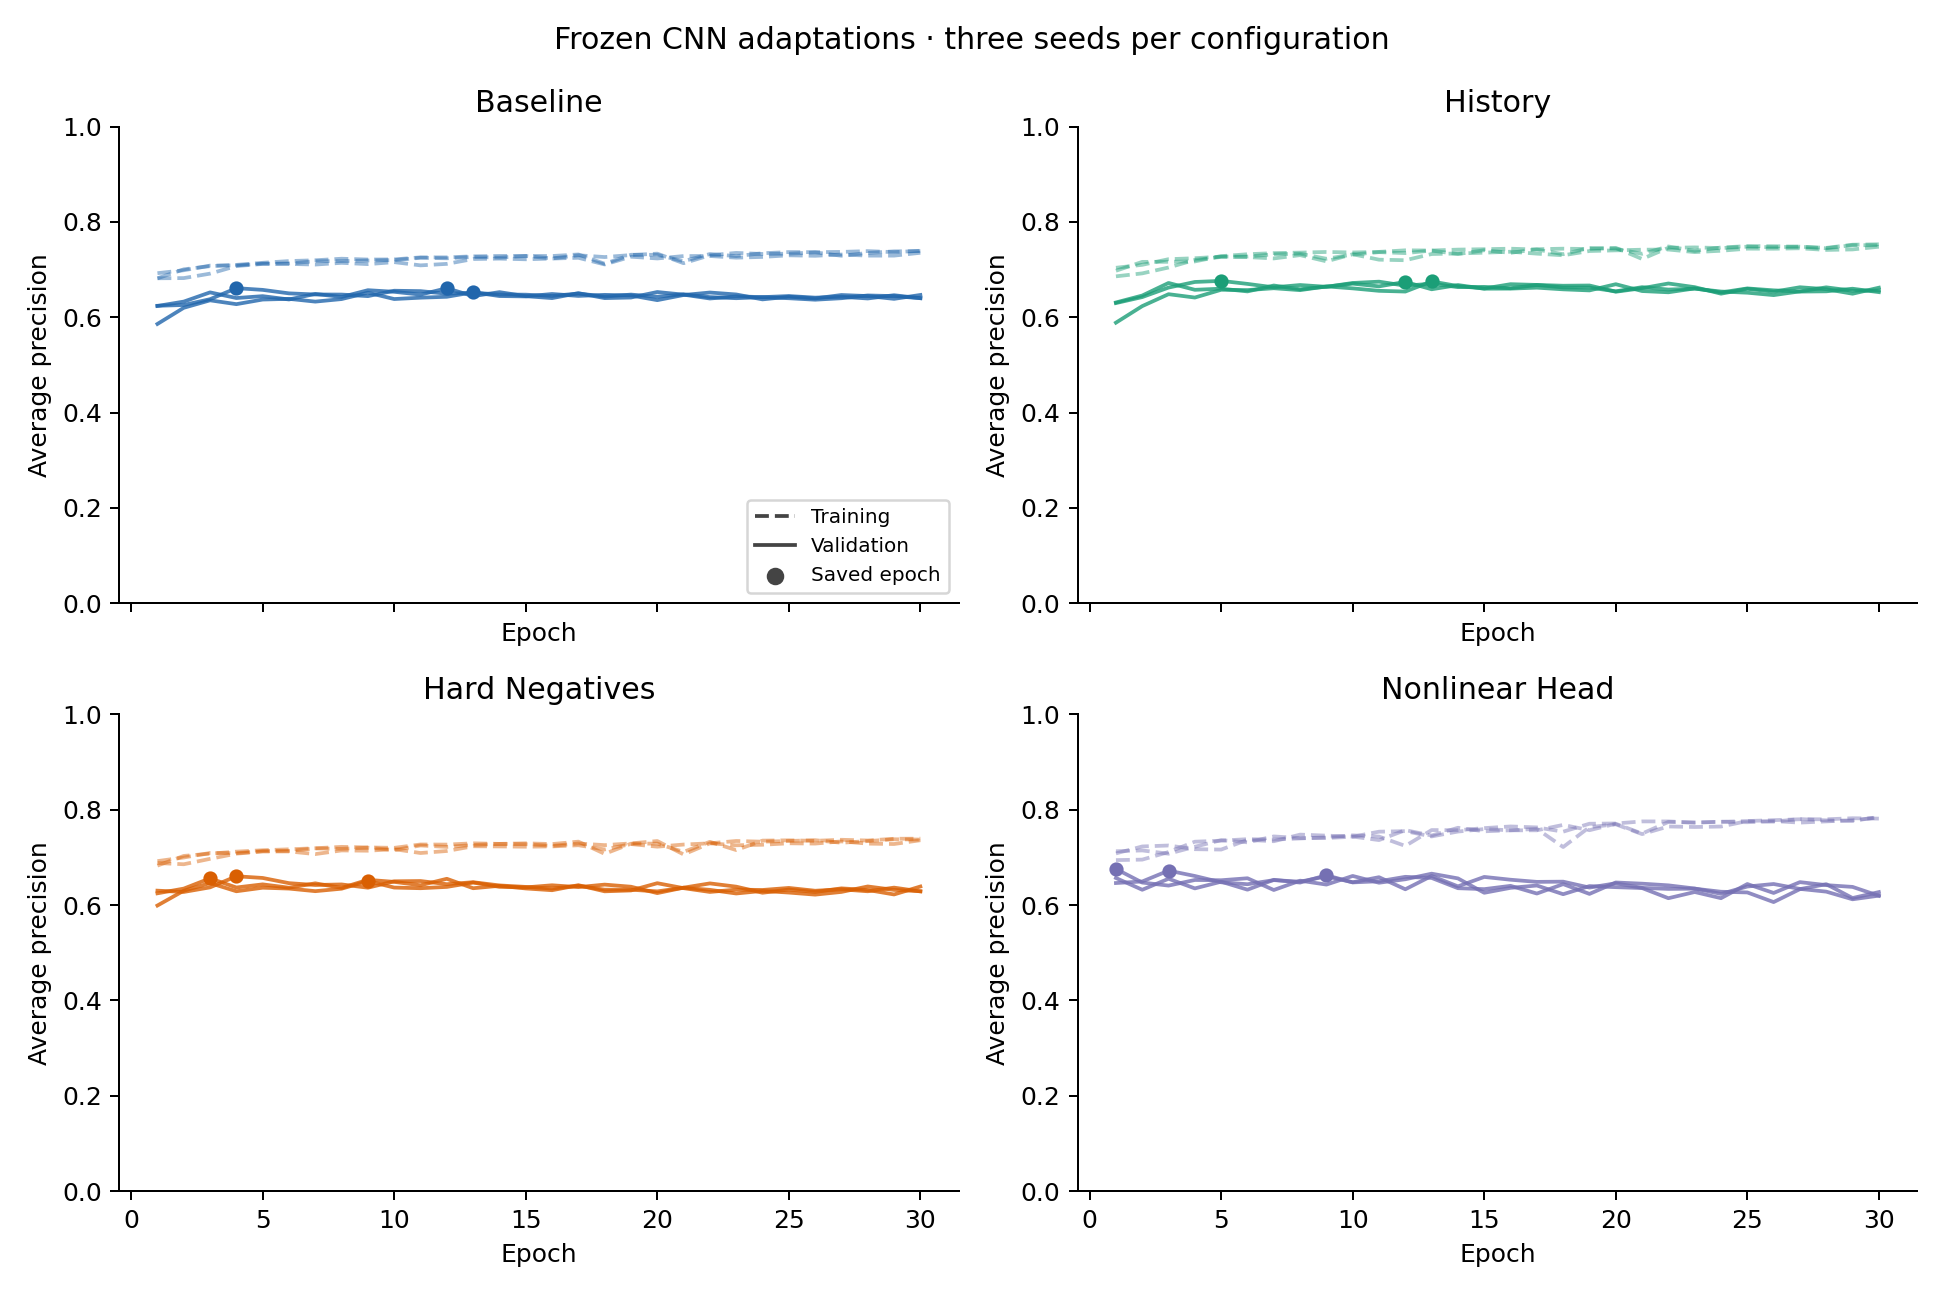

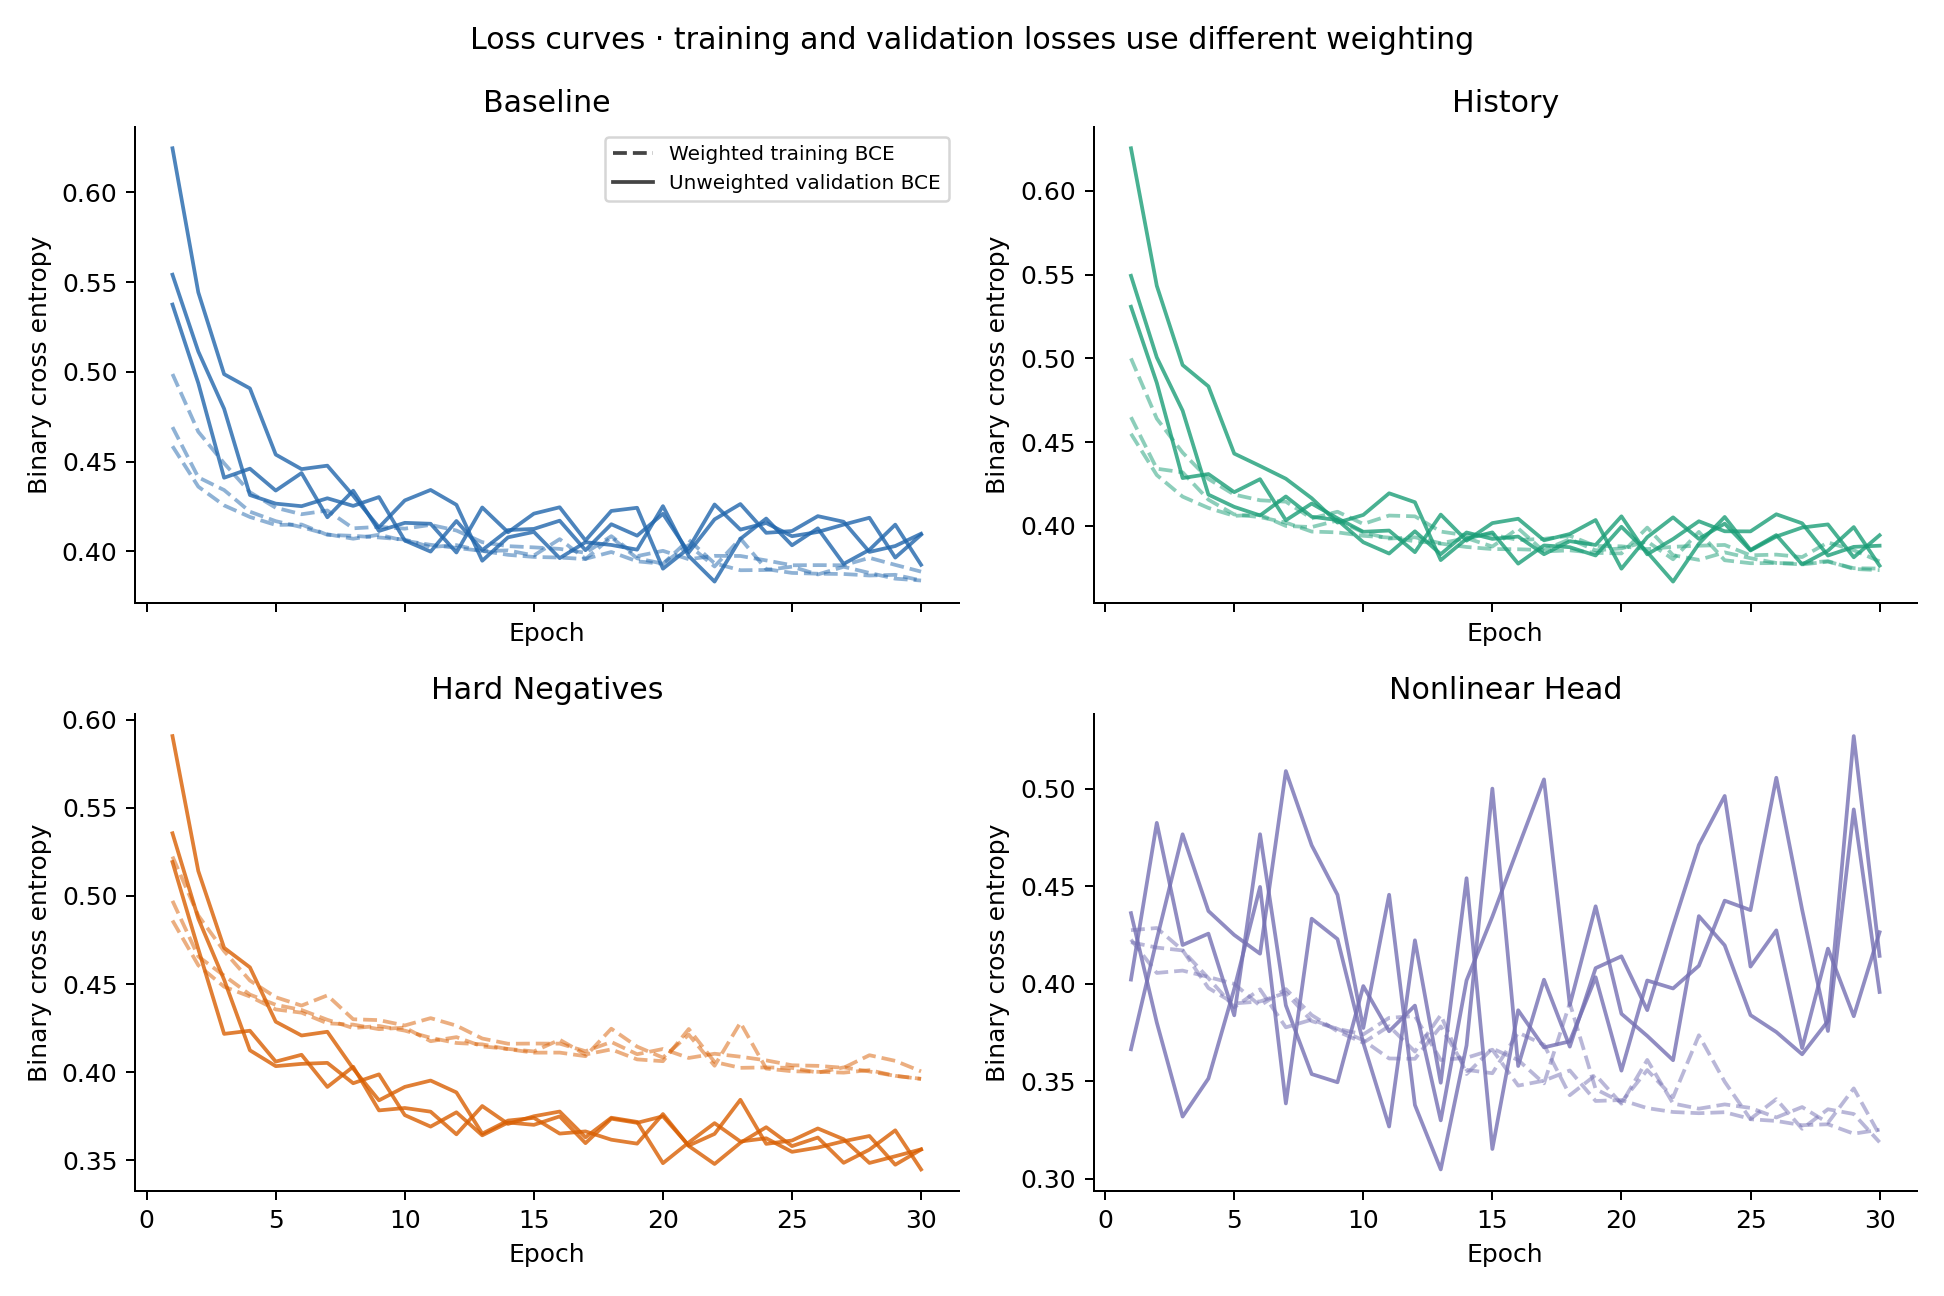

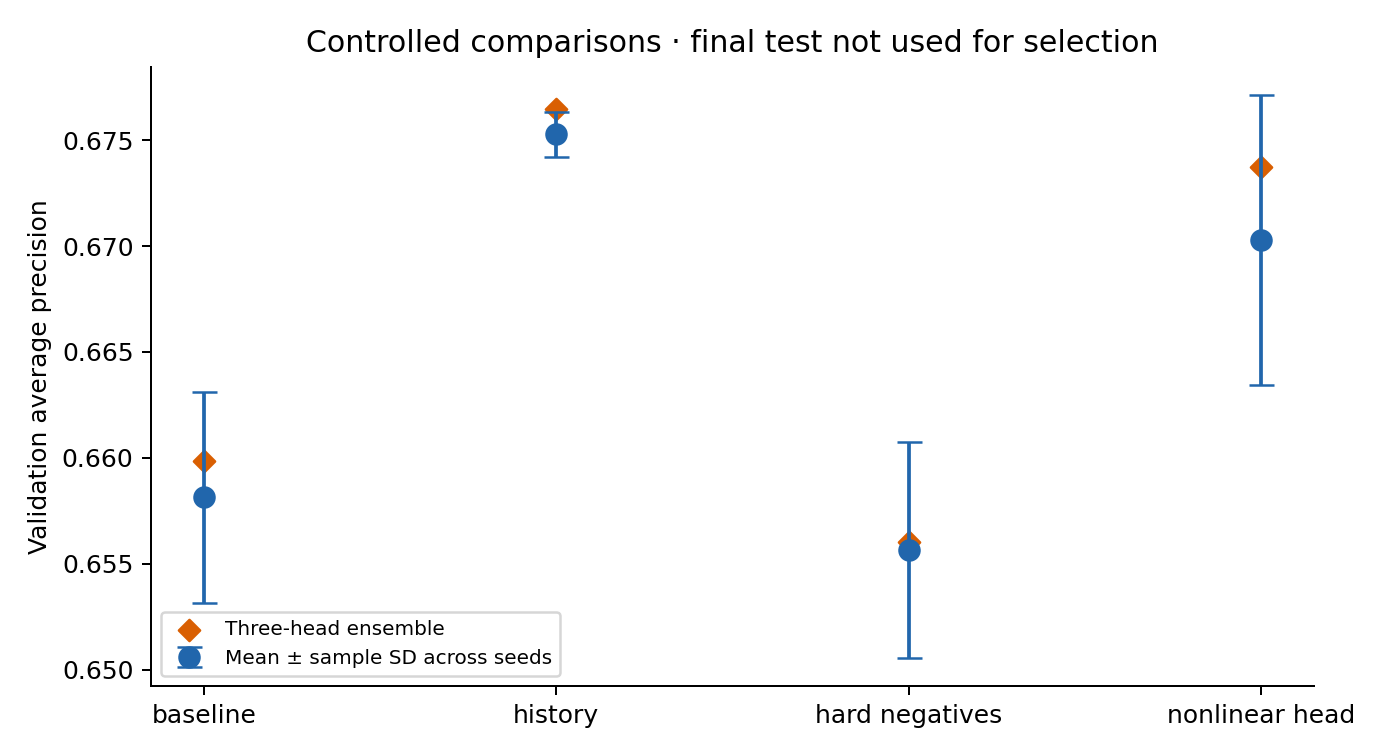

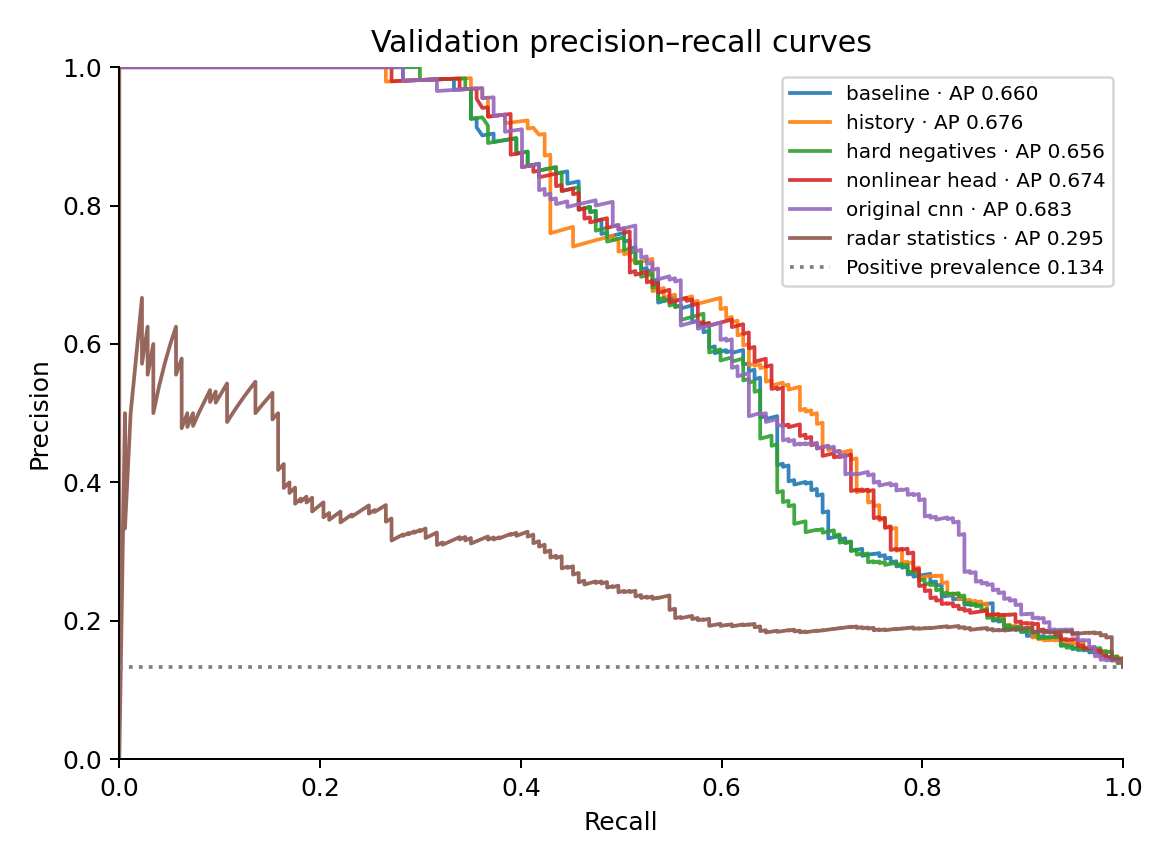

,configuration,subgroup,clips,storm_groups,recall,false_positive_rate
0,baseline,quiet_0_to_0,1148,9,NaN,0.340592
1,baseline,onset_0_to_1,62,8,0.774194,NaN
2,baseline,ending_1_to_0,0,0,NaN,NaN
3,baseline,persisting_1_to_1,115,8,0.817391,NaN
4,baseline,warning_negative,519,4,NaN,0.506744
5,history,quiet_0_to_0,1148,9,NaN,0.345819
6,history,onset_0_to_1,62,8,0.790323,NaN
7,history,ending_1_to_0,0,0,NaN,NaN
8,history,persisting_1_to_1,115,8,0.808696,NaN
9,history,warning_negative,519,4,NaN,0.506744


In [5]:
for name in ['training_validation_ap','training_validation_loss','validation_comparison','validation_precision_recall']:
    display(Image(filename=str(ROOT / 'results/figures' / (name+'.png')), width=850))
display(pd.read_csv(ROOT / 'results/validation_subgroup_metrics.csv')[['configuration','subgroup','clips','storm_groups','recall','false_positive_rate']])

## Seal and evaluate the final test

The selected three-head ensemble and predeclared references are evaluated after the decision file is locked. The trained baseline remains a predeclared reference; no unselected experimental variant is tested. Each scored model uses its own validation threshold targeting ≥80% recall. The majority classifier predicts the training majority class. Here test_once validates and reuses saved final predictions; it makes no new tuning decisions.

In [6]:
final = test_once()
assert final['status']=='sealed_final_test'
display(pd.DataFrame(final['metrics']).T)
display({'test_clips':final['test_clips'],'test_storm_groups':final['test_storm_groups'],'decision_sha256':final['decision_sha256'],'bootstrap':final['bootstrap']})

,clips,positives,prevalence,average_precision,precision,recall,f1,false_positive_rate,warning_negative_false_positive_rate,warning_negative_clips,accuracy,tn,fp,fn,tp,threshold
history,1422.0,89.0,0.062588,0.547828,0.109005,0.775281,0.191136,0.423106,0.549683,473.0,0.589311,769.0,564.0,20.0,69.0,0.296748
majority,1422.0,89.0,0.062588,0.062588,0.000000,0.000000,0.000000,0.000000,0.000000,473.0,0.937412,1333.0,0.0,89.0,0.0,NaN
original_cnn,1422.0,89.0,0.062588,0.516662,0.197674,0.764045,0.314088,0.207052,0.386892,473.0,0.791139,1057.0,276.0,21.0,68.0,0.037116
radar_statistics,1422.0,89.0,0.062588,0.142377,0.085809,0.876404,0.156313,0.623406,0.858351,473.0,0.407876,502.0,831.0,11.0,78.0,0.347623
baseline,1422.0,89.0,0.062588,0.508106,0.109204,0.786517,0.191781,0.428357,0.545455,473.0,0.585091,762.0,571.0,19.0,70.0,0.316543


{'test_clips': 1422,
 'test_storm_groups': 10,
 'decision_sha256': '164850e7bee0d72a36803aee1c80e2e01eed3277a4c998d50aebaceb31b808f0',
 'bootstrap': {'draws': 1000,
  'seed': 42,
  'unit': 'whole storm group',
  'paired_between_models': True,
  'intervals': 'bootstrap_intervals.csv',
  'interpretation': 'Descriptive with only ten independent groups'}}

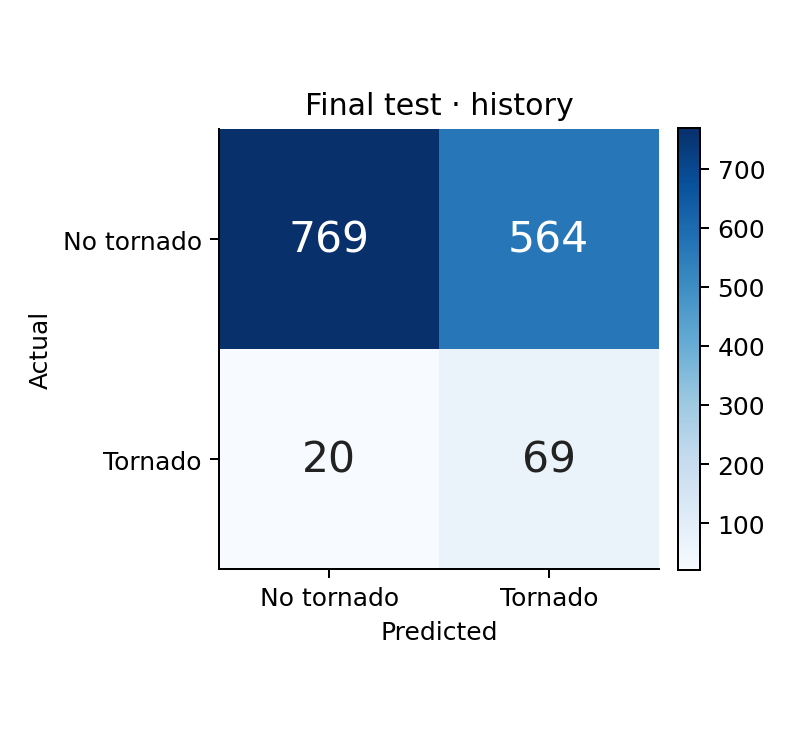

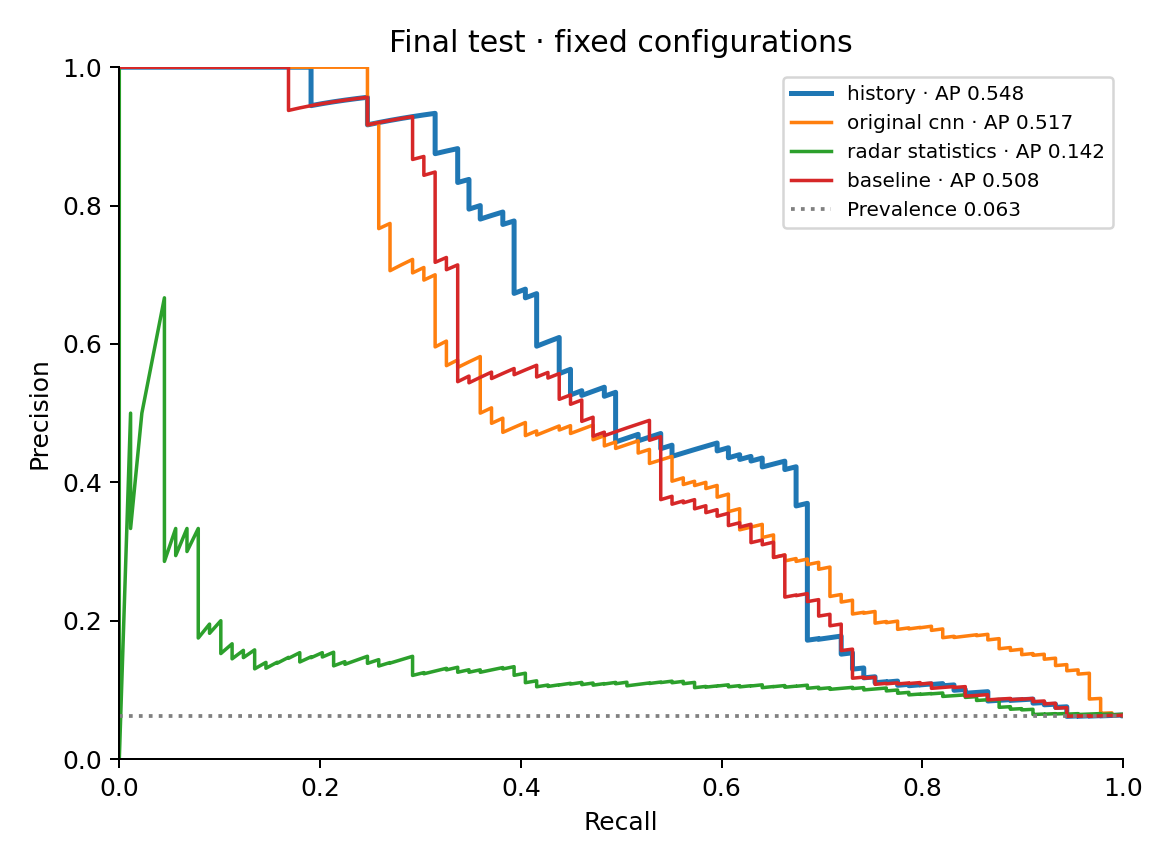

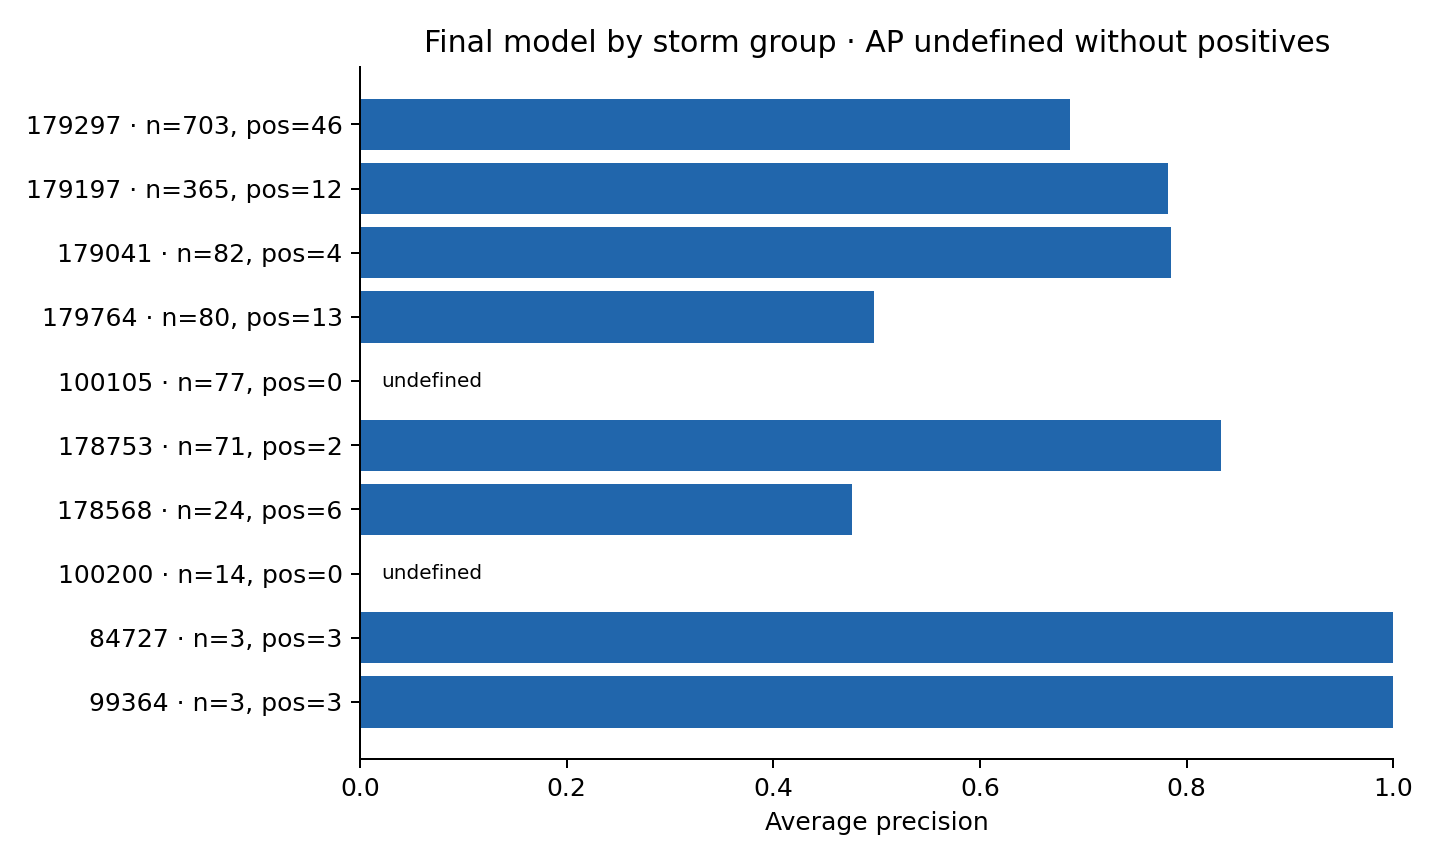

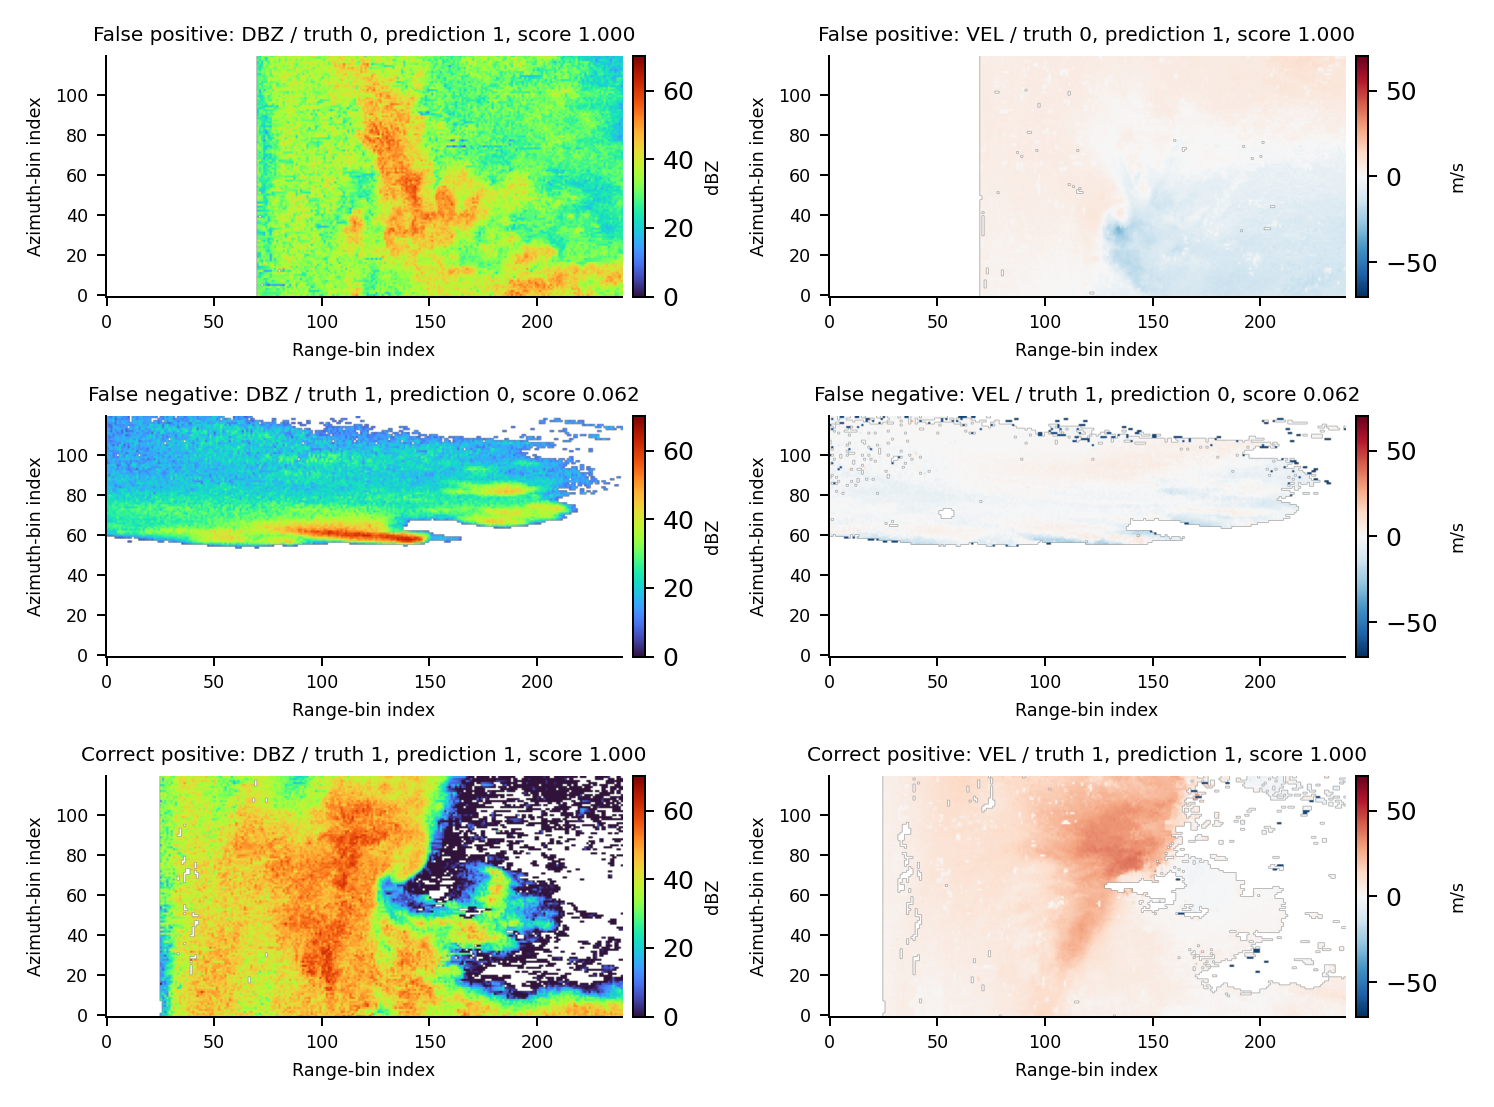

,case,filename,label,prediction,score,category,storm_group
0,False positive,test/2015/WRN_150408_003533_KJKL_1074913n_I1.nc,0,1,0.999848,WRN,179297
1,False negative,test/2014/TOR_140518_235356_KUDX_511791_X0.nc,1,0,0.062176,TOR,84727
2,Correct positive,test/2015/TOR_150407_193102_KVWX_566994_G4.nc,1,1,0.999983,TOR,179297


,kind,model,metric,draws,valid_draws,ci_lower,ci_upper,seed,resampling_unit
0,model_metric,history,average_precision,1000,1000,0.359558,0.657893,42,whole storm group
1,model_metric,history,precision,1000,1000,0.071262,0.146620,42,whole storm group
2,model_metric,history,recall,1000,1000,0.500000,0.884949,42,whole storm group
3,model_metric,history,f1,1000,1000,0.129978,0.241548,42,whole storm group
4,model_metric,history,false_positive_rate,1000,1000,0.339611,0.469598,42,whole storm group
5,model_metric,history,warning_negative_false_positive_rate,1000,1000,0.454335,0.689133,42,whole storm group
6,model_metric,history,accuracy,1000,1000,0.532756,0.658588,42,whole storm group
7,model_metric,majority,average_precision,1000,1000,0.037792,0.120570,42,whole storm group
8,model_metric,majority,precision,1000,1000,0.000000,0.000000,42,whole storm group
9,model_metric,majority,recall,1000,1000,0.000000,0.000000,42,whole storm group


,storm_group,model,clips,positives,prevalence,average_precision,precision,recall,f1,false_positive_rate,warning_negative_false_positive_rate,warning_negative_clips,accuracy,tn,fp,fn,tp,threshold
0,100105,history,77,0,0.000000,NaN,0.000000,NaN,0.000000,0.142857,NaN,0,0.857143,66,11,0,0,0.296748
1,100200,history,14,0,0.000000,NaN,0.000000,NaN,0.000000,0.071429,NaN,0,0.928571,13,1,0,0,0.296748
2,178568,history,24,6,0.250000,0.475731,0.125000,0.333333,0.181818,0.777778,0.916667,12,0.250000,4,14,4,2,0.296748
3,178753,history,71,2,0.028169,0.833333,0.083333,1.000000,0.153846,0.318841,0.276596,47,0.690141,47,22,0,2,0.296748
4,179041,history,82,4,0.048780,0.784483,0.100000,1.000000,0.181818,0.461538,0.823529,17,0.560976,42,36,0,4,0.296748
5,179197,history,365,12,0.032877,0.781815,0.062857,0.916667,0.117647,0.464589,0.539749,239,0.547945,189,164,1,11,0.296748
6,179297,history,703,46,0.065434,0.686770,0.125392,0.869565,0.219178,0.424658,0.554745,137,0.594595,378,279,6,40,0.296748
7,179764,history,80,13,0.162500,0.497245,0.159091,0.538462,0.245614,0.552239,0.809524,21,0.462500,30,37,6,7,0.296748
8,84727,history,3,3,1.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0,0.000000,0,0,3,0,0.296748
9,99364,history,3,3,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,NaN,0,1.000000,0,0,0,3,0.296748


In [7]:
for name in ['final_confusion_matrix','final_precision_recall','final_per_group_ap','example_predictions']:
    display(Image(filename=str(ROOT / 'results/figures' / (name+'.png')), width=850))
display(pd.read_csv(ROOT / 'results/example_cases.csv'))
display(pd.read_csv(ROOT / 'results/bootstrap_intervals.csv'))
display(pd.read_csv(ROOT / 'results/per_group_metrics.csv'))

## Reasoning, unsuccessful attempt and limitations

The following account is generated from actual results. A poorer configuration or development attempt is discussed without inventing an unsuccessful run. Storm-group intervals describe uncertainty from this small, correlated holdout. Scores are not calibrated tornado probabilities.

In [8]:
display(Markdown((ROOT / 'RESULTS.md').read_text(encoding='utf-8')))
from verify_results import verify
display(verify())

# Executed TorNet transfer-learning study

All four configurations were fitted with seeds 42, 43 and 44: **12 completed real-data fits**. Validation selected **Two-scan mean / linear**. Final testing used the locked decision and saved predictions; the holdout was not used for configuration selection.

Actual-label QA passed for 6,414 clips; 0 planned clips were excluded identically for all runs. Targets are the stored terminal-frame labels, not the TOR/WRN/NUL sampling categories.

| Split | Clips | Positives | Storm groups | Positive groups | WRN negatives |
| --- | ---: | ---: | ---: | ---: | ---: |
| train | 3667 | 438 | 28 | 12 | 1333 |
| val | 1325 | 177 | 10 | 8 | 519 |
| test | 1422 | 89 | 10 | 8 | 473 |

A genuine pre-fit QA failure exposed 2,325 WRN files with legacy embedded event/episode IDs. The authors document corrected warning IDs in v1.1. Filenames match the corrected catalog IDs, and actual terminal timestamps match the catalog exactly. We use catalog IDs for grouping, retain embedded IDs as diagnostics, and keep strict ID equality for TOR/NUL. Frame labels and the predeclared split are unchanged; the failed audit is preserved.

The backbone was frozen and used only as a feature extractor. Each run trained a new head. Embedded checkpoint normalization and missing-value handling were preserved; the public loader and repeated-inference checks passed.

| Configuration | Mean validation AP ± SD | Ensemble validation AP | Head parameters | Head fit seconds (3 seeds) |
| --- | ---: | ---: | ---: | ---: |
| Current scan / linear | 0.658 ± 0.005 | 0.660 | 385 | 3.2 |
| Two-scan mean / linear | 0.675 ± 0.001 | 0.676 | 385 | 2.4 |
| Warning negatives x2 | 0.656 ± 0.005 | 0.656 | 385 | 2.4 |
| Current scan / MLP | 0.670 ± 0.007 | 0.674 | 24,705 | 3.6 |

Configurations within 0.01 AP of the highest mean favor fewer parameters, then one scan, then declared order. Each experiment changed one major factor relative to the baseline; changes were not combined. Each scored model received its own validation threshold targeting at least 80% recall. This does not guarantee 80% test recall.

Warning negatives x2 was a genuine less-successful adaptation. Giving non-tornadic warning examples more weight might reduce false alarms. Mean validation AP was 0.656, versus 0.658 for the baseline (difference -0.003). Warning labels are uncertain; extra negative pressure can also suppress real tornado cues. The authors instead downweighted warning cases. This is a plausible explanation, not an established mechanism. We kept the predeclared comparison and selected the final configuration using all three seeds, without adding the unsuccessful change to other runs. At each model's validation-recall threshold, warning-negative FPR was 0.530 versus 0.507 for baseline; this secondary measure can trade off with overall ranking quality. The AP difference is small relative to seed variation. Rechoosing a threshold to preserve 80% recall can offset a loss-weight change's effect on raw scores, so extra negative weight does not guarantee fewer false alarms.

| Final-test model | AP | Precision | Recall | F1 | Accuracy | WRN-negative FPR |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Two-scan mean / linear | 0.548 | 0.109 | 0.775 | 0.191 | 0.589 | 0.550 |
| Training majority | 0.063 | 0.000 | 0.000 | 0.000 | 0.937 | 0.000 |
| Unchanged TorNet CNN | 0.517 | 0.198 | 0.764 | 0.314 | 0.791 | 0.387 |
| Radar-statistics logistic | 0.142 | 0.086 | 0.876 | 0.156 | 0.408 | 0.858 |
| Current scan / linear | 0.508 | 0.109 | 0.787 | 0.192 | 0.585 | 0.545 |

Validation prevalence is 0.134; test prevalence is 0.063. Precision and AP depend on prevalence, so compare configurations within the same fixed split rather than treating the validation-to-test AP change as a pure measure of overfitting.

At the locked validation-derived thresholds, the adaptation detected 69 positive clips versus 68 for the unchanged CNN, but produced 564 false positives versus 276. AP describes overall ranking, while these counts describe one operating point. We retain the validation-selected configuration as this experiment's final adaptation; the evidence does not support warning deployment.

Adaptation minus unchanged-CNN test AP: +0.031; descriptive 95% paired storm-group bootstrap interval [-0.061, 0.155]. An interval containing zero does not establish a robust ranking improvement.

The final set contains 1,422 clips in only 10 storm groups. Paired storm-group bootstrap intervals and per-group metrics are in results/. Adjacent clips are correlated; these are descriptive uncertainty estimates rather than evidence of operational reliability.

Measured feature extraction: 201.0 seconds. Longest individual head fit: 1.5 seconds. These timings exclude downloading the two full archives (32.46 GB decimal) and include no claim about a production system.

The example figure uses the highest-scoring false positive, lowest-scoring false negative, and one seeded correct positive when those cases exist. Selection occurred after the final result was sealed; examples did not drive training decisions.

Limitations: current tornado detection, not advance forecasting; retrospective event-centered crops; two years and few independent storm groups; selected-case prevalence; uncertain warning labels; source-training exclusion relies on documented authors' practice rather than checkpoint sample metadata; other episodes on the same weather days may have been in pretraining. Class-weighted sigmoid scores are not calibrated tornado probabilities.

In the predeclared pool, 1,667/6,414 clips share a terminal calendar date with authors' source-training records (21/79 dates). This is date overlap, not evidence of duplicate samples or necessarily the same weather system; it limits claims about backbone exposure.

The committed pre-run configuration remains unchanged, including its historical planning status. Completion is documented by data_audit.json, feature_provenance.json, all twelve run rows, final_decision.json and final_test.json.

This is a technical study draft for team review. It does not supply signatures, personal contribution claims or peer evaluations. Both students must review the code and reasoning before submitting the report.

Sources and attribution:

- [A Benchmark Dataset for Tornado Detection and Prediction using Full-Resolution Polarimetric Weather Radar Data (2025)](https://journals.ametsoc.org/view/journals/aies/4/1/AIES-D-24-0006.1.xml)
- [Authors' accessible preprint](https://arxiv.org/html/2401.16437v1)
- [TorNet code and distribution notice](https://github.com/mit-ll/tornet)
- [Public pretrained checkpoint](https://huggingface.co/tornet-ml/tornado_detector_baseline_v1)
- [2014 v1.1 data / CC BY 4.0](https://zenodo.org/records/12637032)
- [2015 v1.1 data / CC BY 4.0](https://zenodo.org/records/12655151)

MIT Lincoln Laboratory TorNet data: CC BY 4.0 as recorded by the official archive metadata; retain its release notice. TorNet software: MIT license. Checkpoint revision and upstream source commit are recorded in provenance.


{'status': 'passed',
 'verified_at_utc': '2026-10-09T22:33:41.736019+00:00',
 'real_runs': 12,
 'shared_input_fingerprint': '63c7a1907bdf0e1940f70c3f8188319cbf203911e2daf174738803ddfdb78a75',
 'selected_configuration': 'history',
 'checked_test_models': ['history',
  'majority',
  'original_cnn',
  'radar_statistics',
  'baseline'],
 'test_clips': 1422,
 'test_storm_groups': 10,
 'validation_threshold_checks': {'history': {'threshold': 0.29674825072288513,
   'validation_recall': 0.8022598870056498},
  'original_cnn': {'threshold': 0.037115760147571564,
   'validation_recall': 0.8022598870056498},
  'radar_statistics': {'threshold': 0.34762346645069836,
   'validation_recall': 0.8022598870056498},
  'baseline': {'threshold': 0.3165431320667267,
   'validation_recall': 0.8022598870056498}},
 'checks': ['Passed real physical-data and feature QA receipts',
  'Exact twelve-run shared input fingerprint',
  'All checkpoint and learning-curve hashes',
  'Thirty-epoch budgets and earliest vali

## Team submission

This notebook and the four-page PDF are technical artifacts for Jeffrey and Jake to review together. The team charter, individual contribution statements and private peer evaluations must describe real participation; this notebook does not fabricate them. Both teammates should be able to explain the label policy, grouped split, frozen backbone, four comparisons, validation selection and errors.